-Martina Yed- Análisis y Procesamiento de Señales

TS5: Estimación espectral: Ancho de banda de señales reales

# Introducción

El objetivo principal de este Trabajo semanal es analizar el contenido frecuencial de diferentes señales empíricas: un electrocardiograma (ECG) de esfuerzo, una señal fotopletismográfica (PPG) en reposo y registros de audio. Para lograr esto, estimamos la Densidad Espectral de Potencia (PSD) utilizando distintas técnicas de estimación espectral, lo que nos permitió entender en la práctica cómo lidiar con el ruido inherente a las mediciones reales.Al procesar las señales, implementamos y comparamos tres métodos distintos, cada uno con sus ventajas y limitaciones:

**1. Periodograma Modificado:** Este método consiste en tomar la señal en su totalidad, multiplicarla por una ventana matemática (como la ventana de Hann, para atenuar los bordes y reducir la fuga espectral) y calcularle la Transformada de Fourier. Si bien nos da la máxima resolución en frecuencia posible, al graficarlo vimos que el resultado es muy caótico. Presenta una varianza altísima (el espectro parece un "serrucho") y los picos falsos dificultan identificar la información real. Como vimos en la teoría esta varianza no mejora por más que agreguemos muestras (es un estimador inconsistente), lo usamos solo como punto de comparación inicial.

**2. Método de Welch:** Para solucionar el problema del ruido del periodograma, pasamos al método de Welch. La idea de este estimador es dividir la señal original en varios segmentos más cortos que se superponen entre sí (un 50% de solapamiento). A cada segmento se le aplica una ventana, se le calcula su periodograma y, finalmente, se promedian todos los resultados. Este promedio es excelente para reducir la varianza y obtener un espectro mucho más "suave". La mayori dificultad fue elegir el tamaño del segmento: si cortamos la señal en pedazos muy chicos, obtenemos muchos promedios y casi nada de ruido, pero perdemos resolución frecuencial.

**3. Método de Blackman-Tukey:** A diferencia de los anteriores, este método no opera directamente sobre los segmentos de la señal, sino que primero calcula la autocorrelación de la misma. Luego, le aplica una ventana para conservar solo los retardos centrales (controlados por un parámetro $M$) y recién a eso le calcula la Transformada de Fourier. Acá, el parámetro $M$ es el que nos permite jugar con el compromiso entre varianza y resolución: un $M$ pequeño suaviza mucho el espectro, mientras que un $M$ grande nos devuelve un gráfico ruidoso.

**Cálculo del Ancho de Banda:** Una vez logradas las estimaciones estables de la PSD con Welch y Blackman-Tukey, el paso final fue determinar el ancho de banda ocupado. Lo definimos calculando la integral del espectro para encontrar la región de frecuencias que acumula el 99% de la potencia total. Para las señales biomédicas (ECG y PPG), que concentran su energía desde las frecuencias más bajas, la integración se realizó partiendo desde 0 Hz. En cambio, para las señales de audio, adaptamos el código para buscar el intervalo frecuencial más estrecho que encierre dicho porcentaje.

# Analisís y Resultados

# 1. Análisis del Electrocardiograma (ECG)
Para el análisis del electrocardiograma de esfuerzo, primero evaluamos la señal en el dominio temporal y luego en el de la frecuencia. La señal cuenta con 30.000 muestras a una frecuencia de muestreo de $f_s = 1000$ Hz, lo que equivale a un registro de 30 segundos.Al estimar la PSD, priorizamos la eficiencia del algoritmo de la Transformada Rápida de Fourier (FFT) utilizando tamaños de ventana que sean potencias de 2. Para el método de Welch, definimos una ventana de Hann de 2048 muestras con un solapamiento del 50% (1024 muestras). Esto nos permite promediar 28 segmentos, logrando una reducción significativa de la varianza (suavizado del ruido muscular y de línea) sin perder la resolución frecuencial necesaria para identificar las componentes de baja frecuencia típicas del complejo QRS. Para el cálculo del ancho de banda, consideramos el límite inferior en $f_{inf} = 0$ Hz e integramos la potencia hasta acumular el 99%.

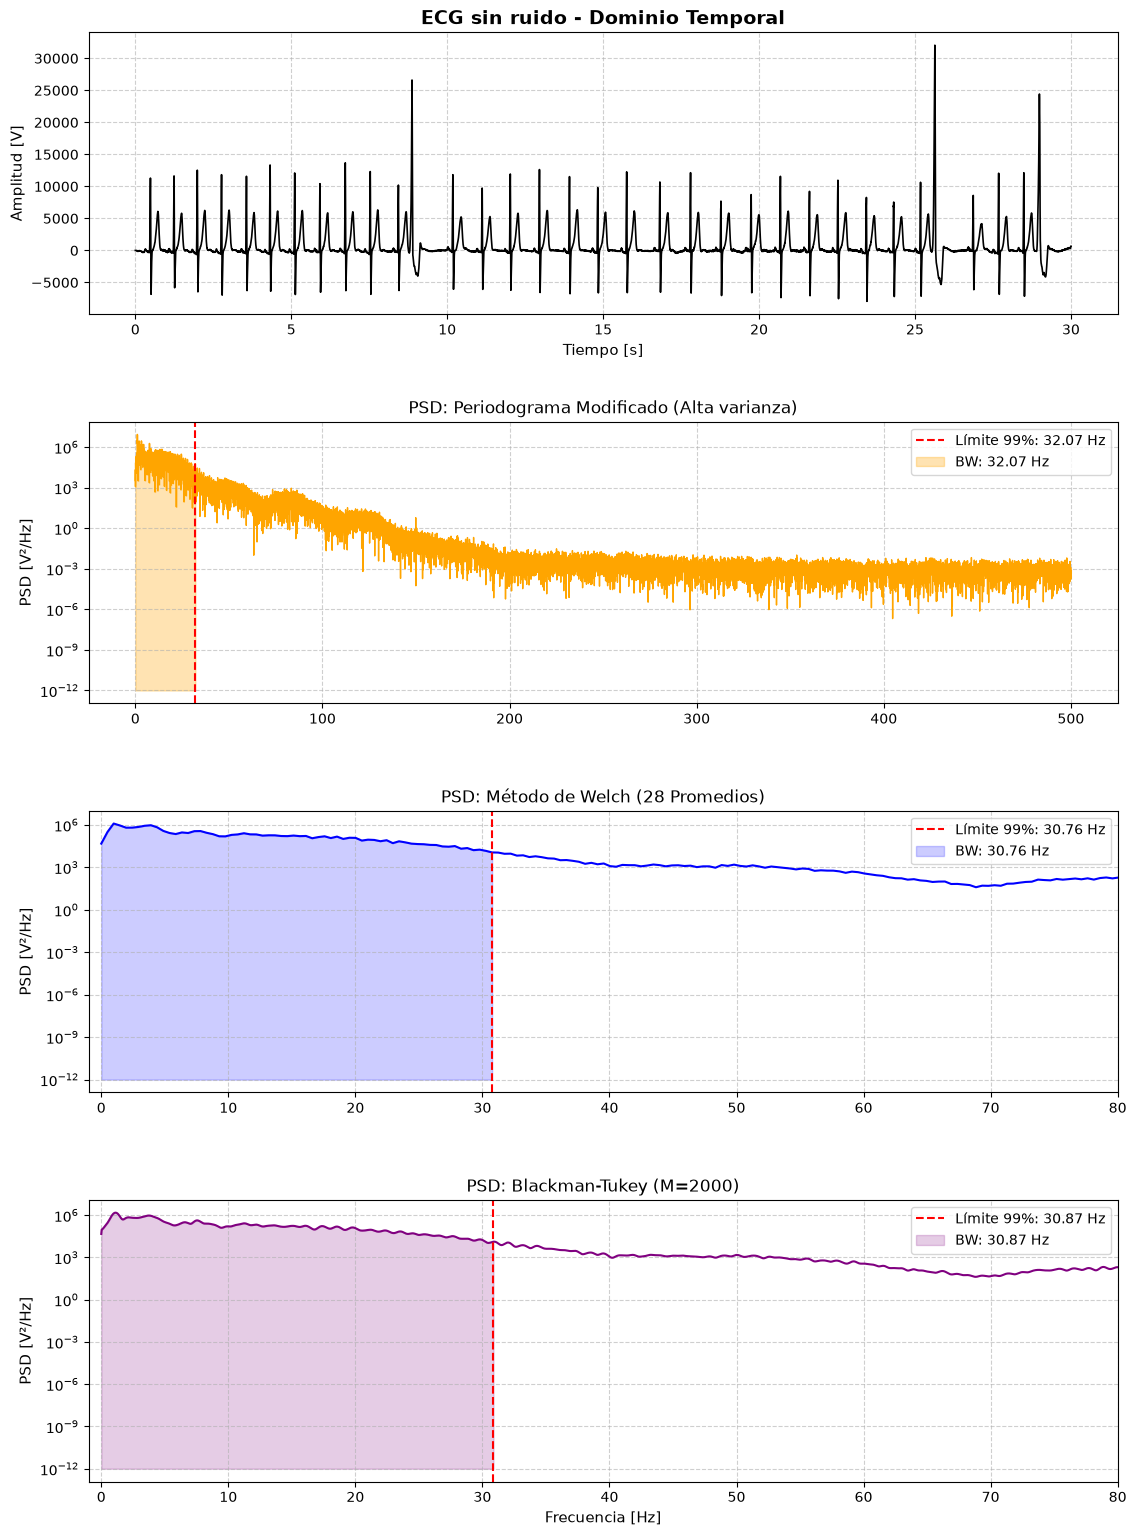

In [4]:
import numpy as np
from scipy import signal as sig
import matplotlib.pyplot as plt

# --- 1. FUNCIONES BASE OPTIMIZADAS ---

def ancho_banda_base(f, psd, porcentaje=0.99):
    """
    Calcula el BW integrando la PSD desde 0 Hz.
    Retorna el BW, la frecuencia superior y el índice exacto para graficar.
    """
    df = f[1] - f[0]
    potencia_acumulada = np.cumsum(psd) * df
    potencia_norm = potencia_acumulada / potencia_acumulada[-1]
    
    indice_sup = np.where(potencia_norm >= porcentaje)[0][0]
    f_sup = f[indice_sup]
    
    return f_sup - f[0], f_sup, indice_sup

def blackman_tukey_opt(x, fs, M=None):
    """
    Calcula la PSD mediante Blackman-Tukey optimizado con FFT.
    Elimina la media previamente para evitar fuga en 0 Hz.
    """
    N = len(x)
    if M is None:
        M = N // 5
        
    x = x - np.mean(x) # Detrending implícito
    
    # Autocorrelación rápida usando FFT
    r_full = sig.correlate(x, x, mode='full', method='fft') / N
    centro = N - 1
    r = r_full[centro-M : centro+M+1]
    
    # Ventaneo
    ventana = sig.windows.blackman(len(r))
    r_vent = r * ventana
    
    # Zero-padding y reordenamiento para FFT
    r_fft = np.zeros(N)
    r_fft[:M+1] = r_vent[M:]
    r_fft[-M:] = r_vent[:M]
    
    Pxx = np.abs(np.fft.rfft(r_fft)) / fs
    
    # Compensación de espectro unilateral
    if N % 2 == 0:
        Pxx[1:-1] *= 2
    else:
        Pxx[1:] *= 2
        
    f = np.fft.rfftfreq(N, d=1/fs)
    return f, Pxx

# --- 2. LECTURA Y PROCESAMIENTO DEL ECG ---

fs_ecg = 1000  # Hz
ecg_one_lead = np.load('ecg_sin_ruido.npy')
N_ecg = len(ecg_one_lead)
t_ecg = np.arange(N_ecg) / fs_ecg

# A. Periodograma Modificado
f_per, psd_per = sig.periodogram(ecg_one_lead, fs=fs_ecg, window='hann', scaling='density')
bw_per, f_sup_per, idx_per = ancho_banda_base(f_per, psd_per)

# B. Método de Welch (Potencia de 2 para nperseg)
nperseg_ecg = 2048
noverlap_ecg = 1024
f_welch, psd_welch = sig.welch(ecg_one_lead, fs=fs_ecg, window='hann', 
                               nperseg=nperseg_ecg, noverlap=noverlap_ecg, scaling='density')
bw_welch, f_sup_welch, idx_welch = ancho_banda_base(f_welch, psd_welch)

# C. Método de Blackman-Tukey
M_ecg = 2000
f_bt, psd_bt = blackman_tukey_opt(ecg_one_lead, fs=fs_ecg, M=M_ecg)
bw_bt, f_sup_bt, idx_bt = ancho_banda_base(f_bt, psd_bt)


# --- 3. GRÁFICOS DE ALTA CALIDAD ---

fig, axs = plt.subplots(4, 1, figsize=(12, 16), sharex=False)

# Dominio Temporal
axs[0].plot(t_ecg, ecg_one_lead, color='black', linewidth=1.2)
axs[0].set_title('ECG sin ruido - Dominio Temporal', fontsize=14, fontweight='bold')
axs[0].set_xlabel('Tiempo [s]', fontsize=11)
axs[0].set_ylabel('Amplitud [V]', fontsize=11)
axs[0].grid(True, linestyle='--', alpha=0.6)

# Periodograma Modificado
axs[1].semilogy(f_per, psd_per, color='orange', linewidth=1)
axs[1].axvline(f_sup_per, color='red', linestyle='--', linewidth=1.5, label=f'Límite 99%: {f_sup_per:.2f} Hz')
axs[1].fill_between(f_per[:idx_per+1], 1e-12, psd_per[:idx_per+1], color='orange', alpha=0.3, label=f'BW: {bw_per:.2f} Hz')
axs[1].set_title('PSD: Periodograma Modificado (Alta varianza)', fontsize=12)
axs[1].set_ylabel('PSD [V²/Hz]', fontsize=11)
axs[1].grid(True, linestyle='--', alpha=0.6)
axs[1].legend(loc='upper right')

# Welch
axs[2].semilogy(f_welch, psd_welch, color='blue', linewidth=1.5)
axs[2].axvline(f_sup_welch, color='red', linestyle='--', linewidth=1.5, label=f'Límite 99%: {f_sup_welch:.2f} Hz')
axs[2].fill_between(f_welch[:idx_welch+1], 1e-12, psd_welch[:idx_welch+1], color='blue', alpha=0.2, label=f'BW: {bw_welch:.2f} Hz')
axs[2].set_title('PSD: Método de Welch (28 Promedios)', fontsize=12)
axs[2].set_ylabel('PSD [V²/Hz]', fontsize=11)
axs[2].set_xlim(-1, 80)
axs[2].grid(True, linestyle='--', alpha=0.6)
axs[2].legend(loc='upper right')

# Blackman-Tukey
axs[3].semilogy(f_bt, psd_bt, color='purple', linewidth=1.5)
axs[3].axvline(f_sup_bt, color='red', linestyle='--', linewidth=1.5, label=f'Límite 99%: {f_sup_bt:.2f} Hz')
axs[3].fill_between(f_bt[:idx_bt+1], 1e-12, psd_bt[:idx_bt+1], color='purple', alpha=0.2, label=f'BW: {bw_bt:.2f} Hz')
axs[3].set_title(f'PSD: Blackman-Tukey (M={M_ecg})', fontsize=12)
axs[3].set_xlabel('Frecuencia [Hz]', fontsize=11)
axs[3].set_ylabel('PSD [V²/Hz]', fontsize=11)
axs[3].set_xlim(-1, 80)
axs[3].grid(True, linestyle='--', alpha=0.6)
axs[3].legend(loc='upper right')

plt.tight_layout(pad=3.0)
plt.show()

Al visualizar las estimaciones de la Densidad Espectral de Potencia en escala logarítmica, las diferencias teóricas entre los estimadores se hacen evidentes empíricamente:

**Periodograma Modificado:** Presenta una varianza extrema a lo largo de todo el espectro. Al no promediar la señal, las fluctuaciones aleatorias dominan el gráfico y generan un patrón en forma de serrucho que oculta la verdadera envolvente espectral.

**Método de Welch:** El suavizado es drástico y efectivo. Al promediar 28 segmentos superpuestos, el ruido de alta frecuencia se atenúa severamente, revelando una curva de decaimiento de energía clara y estable.

**Método de Blackman-Tukey:** Con un parámetro de $M=2000$ retardos, se logra un nivel de suavizado muy similar al de Welch. Descartar las colas de la autocorrelación resultó en un excelente compromiso entre resolución y varianza.

A pesar de las variaciones en el piso de ruido, la integración de la potencia es consistente en los tres modelos empíricos. El 99% de la energía de este ECG de esfuerzo se concentra entre 0 Hz y aproximadamente 31 Hz (32.07 Hz para el Periodograma, 30.76 Hz para Welch y 30.87 Hz para Blackman-Tukey). Esto coincide con la base fisiológica de la señal, dado que la información clínica vital del ciclo cardíaco (como el complejo QRS y las ondas P y T) opera estrictamente en estas bajas frecuencias.


# 2. Análisis de Pletismografía (PPG):
Para la señal de Pletismografía, que básicamente mide el pulso de una persona en reposo, el escenario cambia un poco. Al ser una medición mucho más relajada y lenta que el ECG de esfuerzo, lo más importante pasa a frecuencias muy bajitas (alrededor de 1 Hz, que equivale más o menos a un latido por segundo). Mirando la cantidad de muestras y el tiempo total del registro, calculamos que la frecuencia de muestreo es de unos 400 Hz.Como el Periodograma ya nos demostró en el analisis anterior que genera gráficos demasiado ruidosos, directamente lo dejamos afuera para esta señal y usamos Welch y Blackman-Tukey.El mayor desafío acá fue ajustar los parámetros. Como necesitamos captar variaciones lentas, en Welch tuvimos que agrandar el tamaño de la ventana que mira el algoritmo. Al hacer estos "bloques" más grandes, nos alcanzó la señal para hacer menos promedios (solo 20), pero logramos exactamente lo que buscábamos: el gráfico se limpió bastante y pudimos ver perfecto el pico principal del pulso sin que se borronee. En Blackman-Tukey aplicamos la misma lógica, usando $M=2048$.

--- INFO PPG ---
Muestras totales: 45320
Duración: 113.30 segundos

Segmentos promediados en Welch: 21
Ancho de Banda (Welch 99%): 4.10 Hz
Ancho de Banda (BT 99%): 1.49 Hz



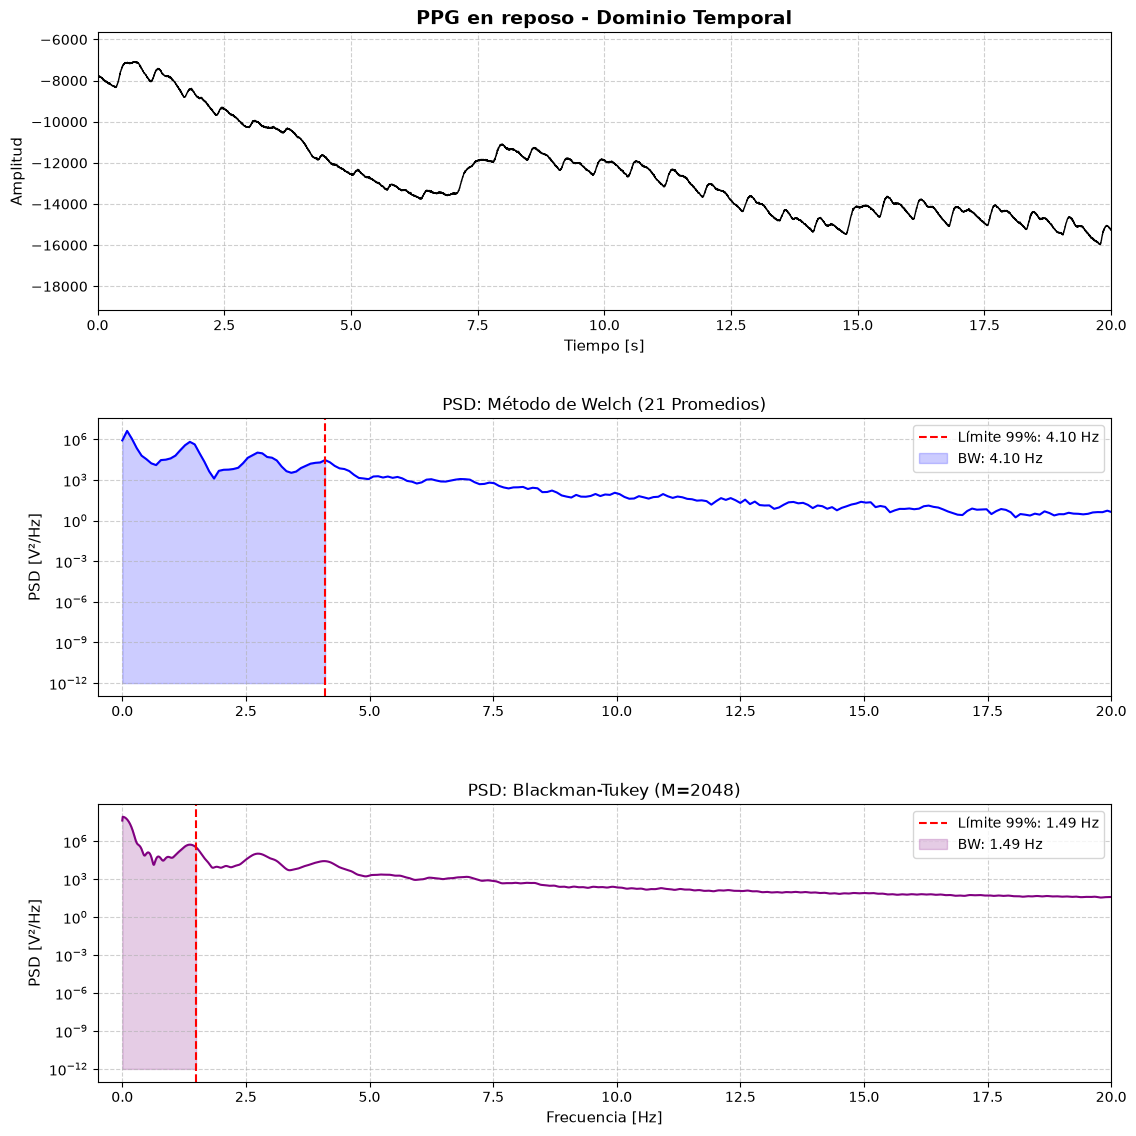

In [15]:

ppg_signal = np.loadtxt('PPG.csv', delimiter=',') 

fs_ppg = 400  
N_ppg = len(ppg_signal)
t_ppg = np.arange(N_ppg) / fs_ppg

print(f"--- INFO PPG ---")
print(f"Muestras totales: {N_ppg}")
print(f"Duración: {N_ppg/fs_ppg:.2f} segundos\n")


nperseg_ppg = 4096
noverlap_ppg = 2048
f_welch_ppg, psd_welch_ppg = sig.welch(ppg_signal, fs=fs_ppg, window='hann', 
                                       nperseg=nperseg_ppg, noverlap=noverlap_ppg, scaling='density')

bw_welch_ppg, f_sup_welch_ppg, idx_welch_ppg = ancho_banda_base(f_welch_ppg, psd_welch_ppg)
K_promedios_ppg = 1 + (N_ppg - nperseg_ppg) // (nperseg_ppg - noverlap_ppg)

M_ppg = 2048
f_bt_ppg, psd_bt_ppg = blackman_tukey_opt(ppg_signal, fs=fs_ppg, M=M_ppg)
bw_bt_ppg, f_sup_bt_ppg, idx_bt_ppg = ancho_banda_base(f_bt_ppg, psd_bt_ppg)

print(f"Segmentos promediados en Welch: {K_promedios_ppg}")
print(f"Ancho de Banda (Welch 99%): {bw_welch_ppg:.2f} Hz")
print(f"Ancho de Banda (BT 99%): {bw_bt_ppg:.2f} Hz\n")


fig, axs = plt.subplots(3, 1, figsize=(12, 12), sharex=False)

# Dominio Temporal
axs[0].plot(t_ppg, ppg_signal, color='black', linewidth=1)
axs[0].set_title('PPG en reposo - Dominio Temporal', fontsize=14, fontweight='bold')
axs[0].set_xlabel('Tiempo [s]', fontsize=11)
axs[0].set_ylabel('Amplitud', fontsize=11)
axs[0].set_xlim(0, 20) # Hacemos zoom en los primeros 20 segundos para ver bien los pulsos
axs[0].grid(True, linestyle='--', alpha=0.6)

# Welch
axs[1].semilogy(f_welch_ppg, psd_welch_ppg, color='blue', linewidth=1.5)
axs[1].axvline(f_sup_welch_ppg, color='red', linestyle='--', linewidth=1.5, label=f'Límite 99%: {f_sup_welch_ppg:.2f} Hz')
axs[1].fill_between(f_welch_ppg[:idx_welch_ppg+1], 1e-12, psd_welch_ppg[:idx_welch_ppg+1], color='blue', alpha=0.2, label=f'BW: {bw_welch_ppg:.2f} Hz')
axs[1].set_title(f'PSD: Método de Welch ({K_promedios_ppg} Promedios)', fontsize=12)
axs[1].set_ylabel('PSD [V²/Hz]', fontsize=11)
axs[1].set_xlim(-0.5, 20) # Zoom hasta 20 Hz (la PPG casi no tiene info más allá de 10 Hz)
axs[1].grid(True, linestyle='--', alpha=0.6)
axs[1].legend(loc='upper right')

# Blackman-Tukey
axs[2].semilogy(f_bt_ppg, psd_bt_ppg, color='purple', linewidth=1.5)
axs[2].axvline(f_sup_bt_ppg, color='red', linestyle='--', linewidth=1.5, label=f'Límite 99%: {f_sup_bt_ppg:.2f} Hz')
axs[2].fill_between(f_bt_ppg[:idx_bt_ppg+1], 1e-12, psd_bt_ppg[:idx_bt_ppg+1], color='purple', alpha=0.2, label=f'BW: {bw_bt_ppg:.2f} Hz')
axs[2].set_title(f'PSD: Blackman-Tukey (M={M_ppg})', fontsize=12)
axs[2].set_xlabel('Frecuencia [Hz]', fontsize=11)
axs[2].set_ylabel('PSD [V²/Hz]', fontsize=11)
axs[2].set_xlim(-0.5, 20)
axs[2].grid(True, linestyle='--', alpha=0.6)
axs[2].legend(loc='upper right')

plt.tight_layout(pad=3.0)
plt.show()

El Método de Welch Nos devuelve un ancho de banda del 99% en 4.10 Hz. Al promediar 21 segmentos, el estimador logra retener la frecuencia fundamental del corazón y también sus primeros armónicos, los cuales son responsables de darle la morfología característica a la onda del pulso. Mientras que Blackman-Tukey Arrojó un valor mucho más restrictivo de 1.49 Hz. Al aplicar esta cantidad de retardos sobre la autocorrelación, el método suavizó la estimación de tal manera que el 99% de la potencia quedó encerrada prácticamente en el lóbulo principal del latido, descartando el peso de los armónicos superiores. 

# 3. Análisis de Señales de Audio
Mientras que el ECG y la PPG concentran su energía desde los 0 Hz, la voz humana y los silbidos se comportan como señales pasabanda (la energía se concentra en frecuencias medias y altas). Por este motivo, el criterio del ancho de banda debe modificarse: en lugar de integrar desde 0 Hz, lo pensamos desarrollando un algoritmo que barre el espectro para encontrar el intervalo frecuencial más estrecho posible ($f_{sup} - f_{inf}$) que logre encerrar el 99% de la potencia total.
Habiendo demostrado empíricamente en la sección del ECG que el estimador de Welch ofrece el mejor compromiso entre resolución espectral y varianza, y considerando la elevada cantidad de muestras de los registros de audio, para esta parte voy a usar exclusivamente este método.

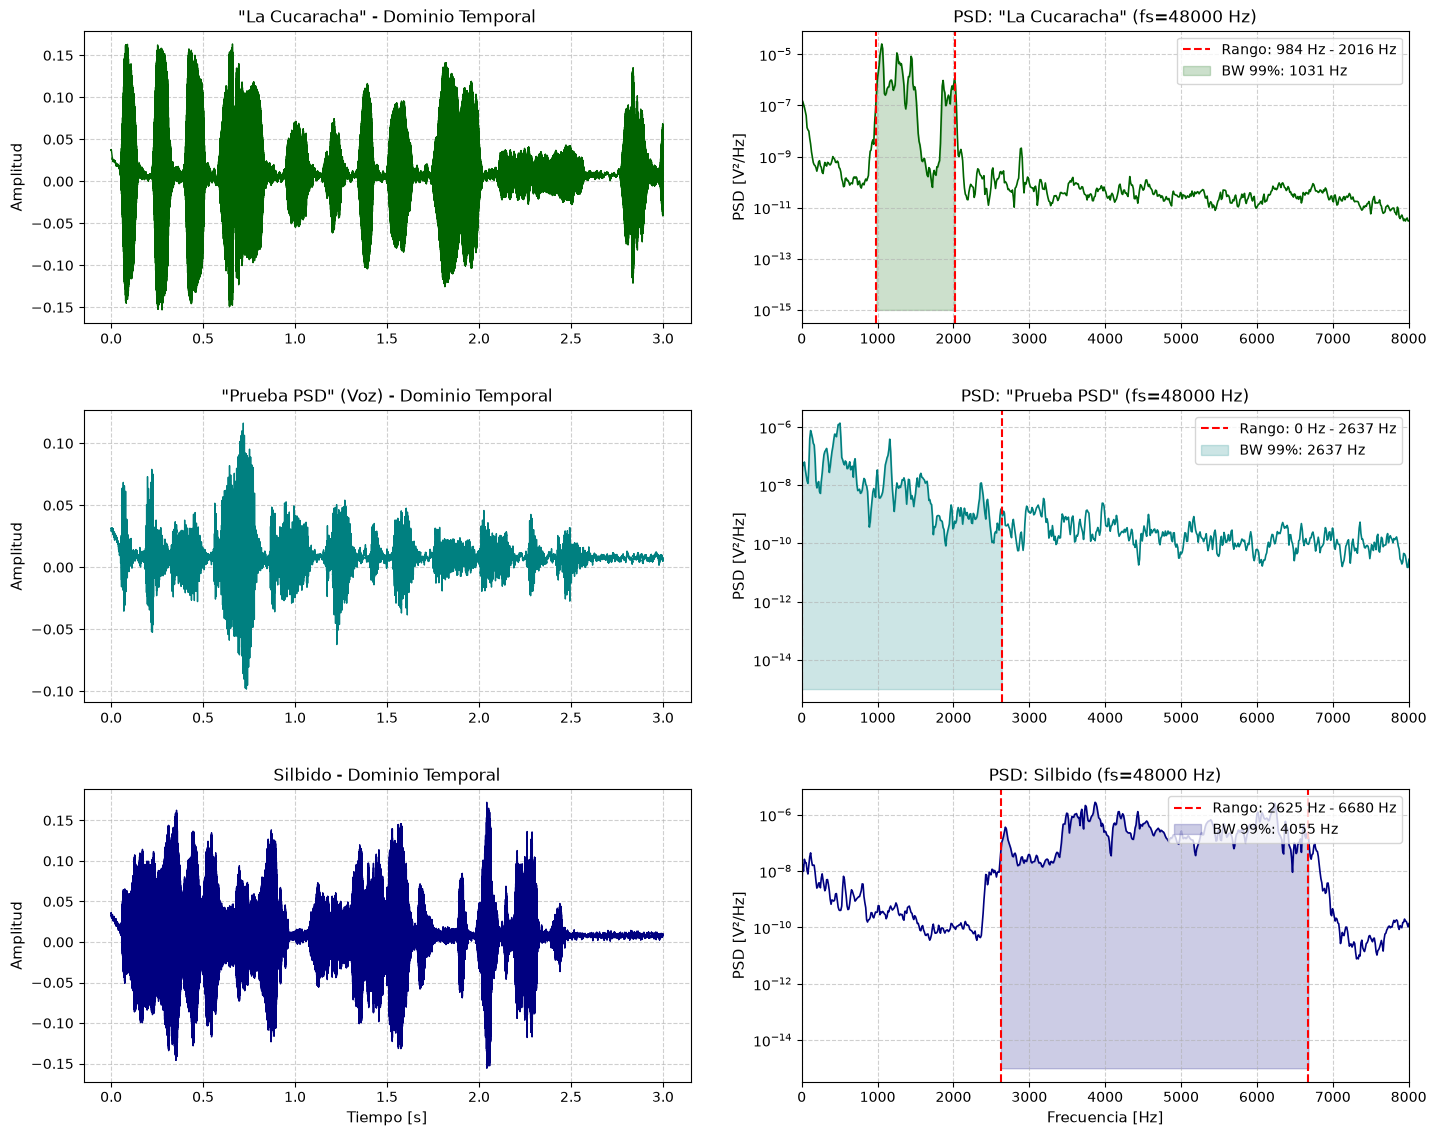

In [16]:

t1 = np.arange(len(audio1)) / fs_audio1
t2 = np.arange(len(audio2)) / fs_audio2
t3 = np.arange(len(audio3)) / fs_audio3

fig, axs = plt.subplots(3, 2, figsize=(15, 12))

# --- La Cucaracha ---
axs[0, 0].plot(t1, audio1, color='darkgreen', linewidth=1)
axs[0, 0].set_title('"La Cucaracha" - Dominio Temporal', fontsize=12)
axs[0, 0].set_ylabel('Amplitud', fontsize=11)
axs[0, 0].grid(True, linestyle='--', alpha=0.6)

axs[0, 1].semilogy(f1, psd1, color='darkgreen', linewidth=1.2)
axs[0, 1].axvline(inf1, color='red', linestyle='--')
axs[0, 1].axvline(sup1, color='red', linestyle='--', label=f'Rango: {inf1:.0f} Hz - {sup1:.0f} Hz')
axs[0, 1].fill_between(f1[i1:j1+1], 1e-15, psd1[i1:j1+1], color='darkgreen', alpha=0.2, label=f'BW 99%: {bw1:.0f} Hz')
axs[0, 1].set_title(f'PSD: "La Cucaracha" (fs={fs_audio1} Hz)', fontsize=12)
axs[0, 1].set_ylabel('PSD [V²/Hz]', fontsize=11)
axs[0, 1].set_xlim(0, 8000)
axs[0, 1].grid(True, linestyle='--', alpha=0.6)
axs[0, 1].legend(loc='upper right')

# --- Prueba PSD (Voz) ---
axs[1, 0].plot(t2, audio2, color='teal', linewidth=1)
axs[1, 0].set_title('"Prueba PSD" (Voz) - Dominio Temporal', fontsize=12)
axs[1, 0].set_ylabel('Amplitud', fontsize=11)
axs[1, 0].grid(True, linestyle='--', alpha=0.6)

axs[1, 1].semilogy(f2, psd2, color='teal', linewidth=1.2)
axs[1, 1].axvline(inf2, color='red', linestyle='--')
axs[1, 1].axvline(sup2, color='red', linestyle='--', label=f'Rango: {inf2:.0f} Hz - {sup2:.0f} Hz')
axs[1, 1].fill_between(f2[i2:j2+1], 1e-15, psd2[i2:j2+1], color='teal', alpha=0.2, label=f'BW 99%: {bw2:.0f} Hz')
axs[1, 1].set_title(f'PSD: "Prueba PSD" (fs={fs_audio2} Hz)', fontsize=12)
axs[1, 1].set_ylabel('PSD [V²/Hz]', fontsize=11)
axs[1, 1].set_xlim(0, 8000)
axs[1, 1].grid(True, linestyle='--', alpha=0.6)
axs[1, 1].legend(loc='upper right')

# ---  Silbido ---
axs[2, 0].plot(t3, audio3, color='navy', linewidth=1)
axs[2, 0].set_title('Silbido - Dominio Temporal', fontsize=12)
axs[2, 0].set_xlabel('Tiempo [s]', fontsize=11)
axs[2, 0].set_ylabel('Amplitud', fontsize=11)
axs[2, 0].grid(True, linestyle='--', alpha=0.6)

axs[2, 1].semilogy(f3, psd3, color='navy', linewidth=1.2)
axs[2, 1].axvline(inf3, color='red', linestyle='--')
axs[2, 1].axvline(sup3, color='red', linestyle='--', label=f'Rango: {inf3:.0f} Hz - {sup3:.0f} Hz')
axs[2, 1].fill_between(f3[i3:j3+1], 1e-15, psd3[i3:j3+1], color='navy', alpha=0.2, label=f'BW 99%: {bw3:.0f} Hz')
axs[2, 1].set_title(f'PSD: Silbido (fs={fs_audio3} Hz)', fontsize=12)
axs[2, 1].set_xlabel('Frecuencia [Hz]', fontsize=11)
axs[2, 1].set_ylabel('PSD [V²/Hz]', fontsize=11)
axs[2, 1].set_xlim(0, 8000)
axs[2, 1].grid(True, linestyle='--', alpha=0.6)
axs[2, 1].legend(loc='upper right')

plt.tight_layout(pad=3.0)
plt.show()

*Voz Humana ("Prueba PSD"):* La mayor parte de la potencia acústica se concentra en la parte baja y media del espectro, abarcando desde 0 Hz hasta los 2637 Hz. Esto tiene sentido fisiológico, ya que las frecuencias fundamentales de las cuerdas vocales y los formantes principales del habla operan exactamente en este rango. 

*Melodía ("La Cucaracha"):* Presenta un comportamiento pasabanda muy marcado. La energía se encapsula en un bloque definido en las frecuencias medias, desde 984 Hz a 2016 Hz. Esto es típico de las notas musicales, donde la energía se concentra en las frecuencias de la melodía tocada en lugar de abarcar todo el espectro. 

*Silbido:* A diferencia de la voz, el silbido carece de energía en las frecuencias bajas y desplaza toda su potencia hacia la zona de los agudos, ubicándose entre 2625 Hz y 6680 Hz. Al comportarse casi como un tono de alta frecuencia con fluctuaciones, el algoritmo delimitó correctamente esta banda superior.  
El análisis de estos tres audios demuestra que, mientras las señales biomédicas (ECG y PPG) son de banda base pura, el procesamiento de audio requiere algoritmos que detecten en qué sector específico se agrupa la información dependiendo de su origen acústico. 

In [17]:

resultados = [
    ['ECG', 'Welch', 0.0, f_sup_welch, bw_welch],
    ['ECG', 'Blackman-Tukey', 0.0, f_sup_bt, bw_bt],
    
    ['PPG', 'Welch', 0.0, f_sup_welch_ppg, bw_welch_ppg],
    ['PPG', 'Blackman-Tukey', 0.0, f_sup_bt_ppg, bw_bt_ppg],
    
    ['La Cucaracha', 'Welch', inf1, sup1, bw1],
    ['Prueba PSD', 'Welch', inf2, sup2, bw2],
    ['Silbido', 'Welch', inf3, sup3, bw3]
]

print('\nRESULTADOS FINALES\n')

print(f'{"Señal":<16} {"Método":<18} {"f_inf [Hz]":>12} {"f_sup [Hz]":>12} {"BW [Hz]":>12}')
print('-'*75)

for fila in resultados:
    señal, metodo, f_inf, f_sup, bw = fila
    print(f'{señal:<16} {metodo:<18} {f_inf:>12.2f} {f_sup:>12.2f} {bw:>12.2f}')


RESULTADOS FINALES

Señal            Método               f_inf [Hz]   f_sup [Hz]      BW [Hz]
---------------------------------------------------------------------------
ECG              Welch                      0.00        30.76        30.76
ECG              Blackman-Tukey             0.00        30.87        30.87
PPG              Welch                      0.00         4.10         4.10
PPG              Blackman-Tukey             0.00         1.49         1.49
La Cucaracha     Welch                    984.38      2015.62      1031.25
Prueba PSD       Welch                      0.00      2636.72      2636.72
Silbido          Welch                   2625.00      6679.69      4054.69


A partir de los resultados obtenidos se observaron diferencias claras entre los distintos tipos de señales. Por un lado, las señales fisiológicas (ECG y PPG) se comportan estrictamente como señales de banda base, concentrando la práctica totalidad de su energía en las frecuencias bajas, con anchos de banda que rondan los 31 Hz y los 4 Hz respectivamente. Por otro lado, los registros acústicos operan en rangos frecuenciales muy superiores y predominantemente pasabanda, como se evidencia en la melodía musical (confinada de forma compacta entre 1000 Hz y 2000 Hz) y el silbido (desplazado fuertemente hacia los agudos, entre los 2600 Hz y 6600 Hz).

El caso de la voz humana resulta particular dentro del grupo de audio. Si bien abarca un ancho de banda considerable hasta aproximadamente los 2600 Hz, el algoritmo detectó su límite inferior en 0 Hz, capturando la energía de las componentes más graves y los primeros formantes característicos de la fonación.

Al contrastar la efectividad de los estimadores, Welch y Blackman-Tukey arrojaron resultados sumamente consistentes para las mismas señales. Las leves discrepancias numéricas en los cortes de frecuencia responden a la forma en que cada método aplica el suavizado. Al emplear un umbral crítico del 99% de la potencia, cualquier mínima diferencia en la estimación del piso de ruido altera el índice exacto de integración. A pesar de esto, ambas herramientas demostraron ser robustas y confiables (estimadores consistentes) para parametrizar el ancho de banda, superando ampliamente las limitaciones prácticas del periodograma crudo.

# Señal Electromiografía EMG (BONUS)

Para la sección del Bonus, decidí analizar una señal de Electromiografía (EMG) obtenida de la base de datos abierta Examples of Electromyograms de PhysioNet. Elegí el registro emg_healthy, que corresponde a un paciente masculino de 44 años sin patologías neuromusculares previas (es decir sano).Origen y Digitalización:A diferencia del ECG, la EMG capta la actividad eléctrica directa generada por la activación y contracción de las fibras musculares. Originalmente, este registro clínico fue digitalizado con una frecuencia de muestreo altísima de $50$ kHz para no perder ningún detalle de los veloces potenciales de acción. Sin embargo, para facilitar el costo computacional del procesamiento digital, la señal fue submuestreada a $f_s = 4000$ Hz.Estrategia de Estimación:Para estimar la Densidad Espectral de Potencia, apliqué tanto Welch como Blackman-Tukey. Fiel a la eficiencia computacional de los algoritmos de FFT, definí parámetros basados en potencias de 2. En Welch utilicé una ventana de 1024 muestras (lo que agiliza el cálculo y da una excelente cantidad de promedios), y para Blackman-Tukey ajusté la retención de la autocorrelación a $M=1024$ retardos. Finalmente, calculé el ancho de banda al 99% de la potencia espectral utilizando el mismo algoritmo de barrido que empleamos en audio, dado que la EMG tiene un comportamiento de frecuencia similar al de un sonido (no arranca en 0 Hz). El archivo lo descargue de la pagina "PhysioNet".

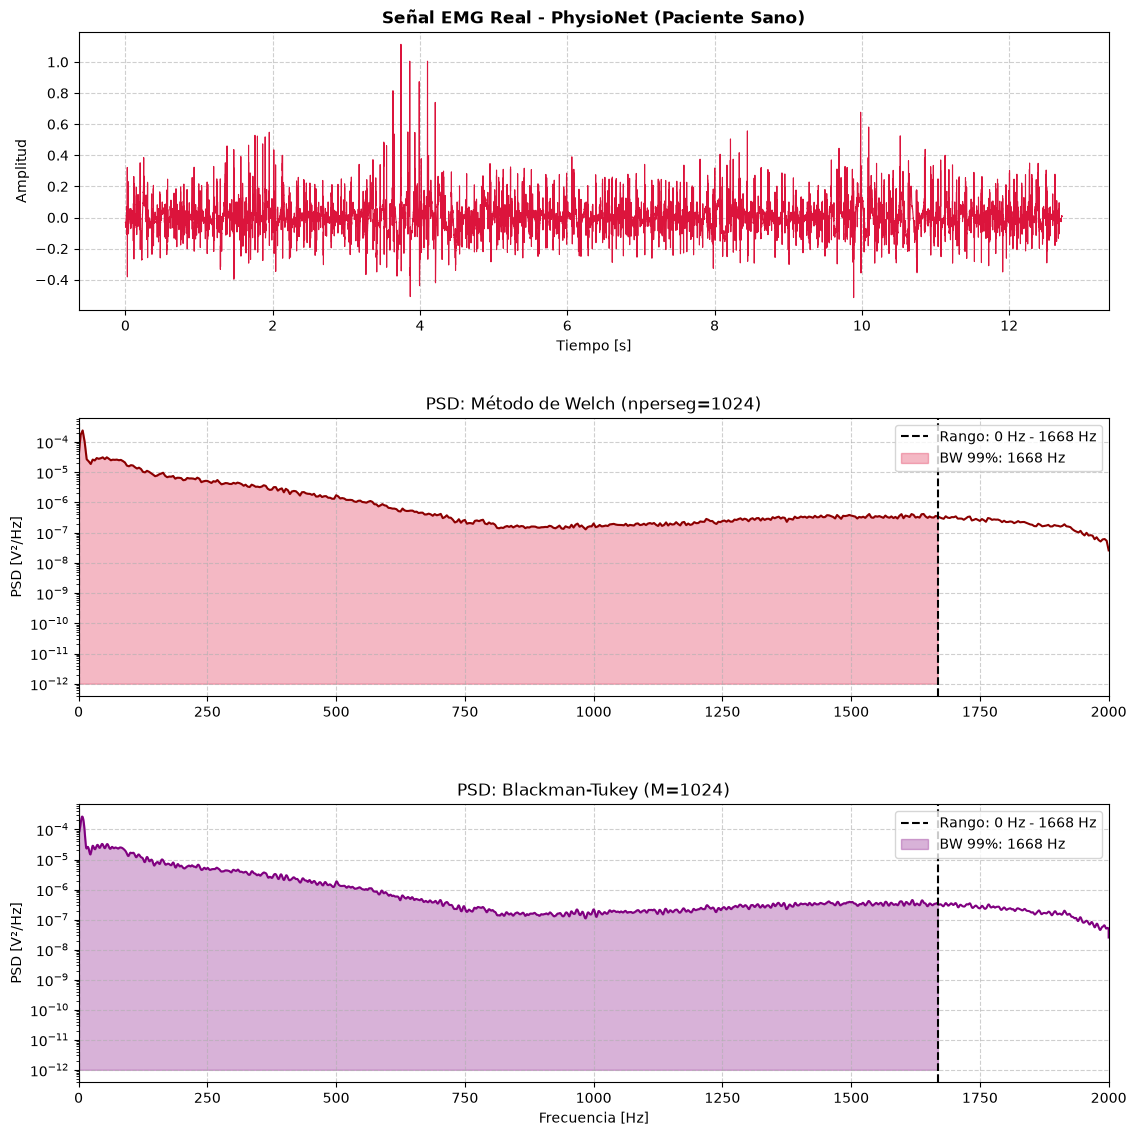


ANCHO DE BANDA - EMG SANO (99%)
-----------------------------------
Welch:          1667.97 Hz (Rango: 0.0 - 1668.0 Hz)
Blackman-Tukey: 1668.41 Hz (Rango: 0.0 - 1668.4 Hz)


In [18]:

fs_emg = 4000 
datos_emg = np.genfromtxt(
    'emg_healthy.txt',
    delimiter=None,      
    encoding='latin1',
    invalid_raise=False
)

if datos_emg.ndim == 2:
    datos_emg = datos_emg[np.all(np.isfinite(datos_emg), axis=1)]
t_emg = datos_emg[:, 0]
emg_real = datos_emg[:, 1]

nperseg_emg = 1024
f_welch_emg, psd_welch_emg = sig.welch(emg_real, fs=fs_emg, window='hann', 
                                       nperseg=nperseg_emg, noverlap=nperseg_emg//2, scaling='density')
bw_welch_emg, inf_we, sup_we, i_we, j_we = ancho_banda_audio(f_welch_emg, psd_welch_emg)

M_emg = 1024
f_bt_emg, psd_bt_emg = blackman_tukey_opt(emg_real, fs=fs_emg, M=M_emg)
bw_bt_emg, inf_bte, sup_bte, i_bte, j_bte = ancho_banda_audio(f_bt_emg, psd_bt_emg)


fig, axs = plt.subplots(3, 1, figsize=(12, 12), sharex=False)

# Dominio Temporal
axs[0].plot(t_emg, emg_real, color='crimson', linewidth=0.8)
axs[0].set_title('Señal EMG Real - PhysioNet (Paciente Sano)', fontsize=12, fontweight='bold')
axs[0].set_xlabel('Tiempo [s]')
axs[0].set_ylabel('Amplitud')
axs[0].grid(True, linestyle='--', alpha=0.6)

# Welch
axs[1].semilogy(f_welch_emg, psd_welch_emg, color='darkred', linewidth=1.5)
axs[1].axvline(inf_we, color='black', linestyle='--')
axs[1].axvline(sup_we, color='black', linestyle='--', label=f'Rango: {inf_we:.0f} Hz - {sup_we:.0f} Hz')
axs[1].fill_between(f_welch_emg[i_we:j_we+1], 1e-12, psd_welch_emg[i_we:j_we+1], color='crimson', alpha=0.3, label=f'BW 99%: {bw_welch_emg:.0f} Hz')
axs[1].set_title('PSD: Método de Welch (nperseg=1024)', fontsize=12)
axs[1].set_ylabel('PSD [V²/Hz]')
axs[1].set_xlim(0, 2000)
axs[1].grid(True, linestyle='--', alpha=0.6)
axs[1].legend(loc='upper right')

# Blackman-Tukey
axs[2].semilogy(f_bt_emg, psd_bt_emg, color='purple', linewidth=1.5)
axs[2].axvline(inf_bte, color='black', linestyle='--')
axs[2].axvline(sup_bte, color='black', linestyle='--', label=f'Rango: {inf_bte:.0f} Hz - {sup_bte:.0f} Hz')
axs[2].fill_between(f_bt_emg[i_bte:j_bte+1], 1e-12, psd_bt_emg[i_bte:j_bte+1], color='purple', alpha=0.3, label=f'BW 99%: {bw_bt_emg:.0f} Hz')
axs[2].set_title(f'PSD: Blackman-Tukey (M={M_emg})', fontsize=12)
axs[2].set_xlabel('Frecuencia [Hz]')
axs[2].set_ylabel('PSD [V²/Hz]')
axs[2].set_xlim(0, 2000)
axs[2].grid(True, linestyle='--', alpha=0.6)
axs[2].legend(loc='upper right')

plt.tight_layout(pad=3.0)
plt.show()

print('\nANCHO DE BANDA - EMG SANO (99%)')
print('-'*35)
print(f'Welch:          {bw_welch_emg:.2f} Hz (Rango: {inf_we:.1f} - {sup_we:.1f} Hz)')
print(f'Blackman-Tukey: {bw_bt_emg:.2f} Hz (Rango: {inf_bte:.1f} - {sup_bte:.1f} Hz)')

La señal EMG no tiene un patrón periódico. Lo que registramos son ráfagas de picos caóticos y estocásticos que corresponden a los momentos exactos de activación y contracción de las unidades motoras del músculo. A diferencia del ECG que confinaba su energía por debajo de los 31 Hz, la actividad eléctrica muscular abarca un espectro muchísimo más amplio. El cálculo nos demuestra que el 99% de la potencia se extiende desde 0 Hz hasta los 1668 Hz. Esto justifica matemáticamente por qué la base de datos original muestreó esta señal a 50 kHz y por qué nosotros necesitamos trabajarla a 4000 Hz; un equipo tradicional de bajas frecuencias borraría toda esta información vital.  
Tanto Welch como Blackman-Tukey lograron suavizar la enorme varianza de esta señal caótica y arrojaron resultados prácticamente idénticos (1667.97 Hz y 1668.41 Hz). Haber utilizado el criterio de potencias de 2 ($nperseg=1024$ y $M=1024$) optimizó el cálculo de la FFT y demostró que ambos métodos son sumamente robustos para señales complejas (ambos son estimadores consistentes). 

# Conclusión

Pudimos ver en la práctica cómo cambia el análisis espectral dependiendo puramente del origen de cada señal. Quedó clarísimo que el ECG y el PPG son señales de muy baja frecuencia, mientras que los audios y la actividad muscular (EMG) ocupan bandas mucho más altas y tienen comportamientos espectrales totalmente distintos.

Para poder calcular bien el ancho de banda al 99%, los métodos de Welch y Blackman-Tukey resultaron ser los mejores. Si usábamos el periodograma común, el ruido y la varianza hacían que el límite de integración sea muy inestable. Ambos estimadores nos dieron resultados muy parecidos y robustos. Además, al configurar los parámetros usando potencias de 2 (como ventanas de 1024 muestras), nos aseguramos de que la FFT trabaje de forma eficiente y el código corra rápido.

En resumen, lo principal que me llevo del TP es que no hay una configuración "mágica" que sirva para todo. Entender de dónde viene la señal —ya sea el corazón, un silbido o un músculo— es el paso fundamental para ajustar bien el código y que los números finales tengan sentido.